## 02- Linear Regression: homework

### Preparing the dataset

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [23]:
cols = [
'engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg'
]

In [24]:
data = pd.read_csv("car_fuel_efficiency_2026.csv").loc[:, cols]
data.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


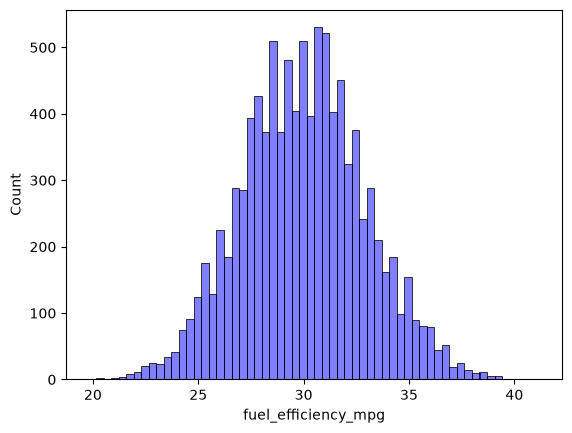

In [25]:
sns.histplot(data.fuel_efficiency_mpg, color = "blue", alpha = .5)
plt.show()

`fuel_efficiency_mpg` does not have a skewed distribution.

### Q1

In [26]:
for colname, nas in pd.DataFrame(data.isnull().sum()).itertuples():
    print(f"{colname} contains {nas} NAs")

engine_displacement contains 0 NAs
horsepower contains 877 NAs
vehicle_weight contains 0 NAs
model_year contains 0 NAs
fuel_efficiency_mpg contains 0 NAs


### Q2

In [27]:
for colname, nas in pd.DataFrame(data.isnull().sum()).itertuples():
    print(f"{colname} contains {nas} NAs")

engine_displacement contains 0 NAs
horsepower contains 877 NAs
vehicle_weight contains 0 NAs
model_year contains 0 NAs
fuel_efficiency_mpg contains 0 NAs


In [28]:
print("The median for horsepower is:", np.percentile(data.dropna().horsepower, 50))

The median for horsepower is: 254.0


In [29]:
n = len(data)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

data_train = data.iloc[idx[:n_train]]
data_val = data.iloc[idx[n_train:n_train + n_val]]
data_test = data.iloc[idx[n_train + n_val:]]

### Q3

In [36]:
# imputation with the mean
def impute(df, value): 
    df = df.copy()
    df["horsepower"] = df["horsepower"].fillna(value)
    return df

mean_train_hp = data_train.dropna().horsepower.mean()

X_train_mean = impute(data_train, mean_train_hp).drop(columns = "fuel_efficiency_mpg")
X_val_mean = impute(data_val, mean_train_hp).drop(columns = "fuel_efficiency_mpg")
X_test_mean = impute(data_test, mean_train_hp).drop(columns = "fuel_efficiency_mpg")

X_train_zero = data_train.fillna(0).drop(columns = "fuel_efficiency_mpg")
X_val_zero = data_val.fillna(0).drop(columns = "fuel_efficiency_mpg")
X_test_zero = data_test.fillna(0).drop(columns = "fuel_efficiency_mpg")

In [37]:
def train_lr(data, y):
    
    data = data.copy()
    X = data.copy()
    X = np.column_stack([np.tile([1], reps = len(X)), X]) \
        .astype('float')

    weights = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)
    return weights

weights_mean = train_lr(X_train_mean, data_train.fuel_efficiency_mpg)
weights_zero = train_lr(X_train_zero, data_train.fuel_efficiency_mpg)

In [38]:
def predict_lr(df, weights):
    df = df.copy()
    df = np.column_stack([np.tile([1], reps=len(df)), df.values])

    return df @ weights

pred_zero = predict_lr(X_val_zero, weights=weights_zero)
pred_mean = predict_lr(X_val_mean, weights = weights_mean)

print(pred_mean, pred_zero)

[31.54288381 29.92505122 31.56459523 ... 30.54408311 30.85701236
 31.55313717] [31.64502134 29.86572978 31.58838899 ... 30.53133298 30.75085098
 31.62912778]


Calculating validation RMSE for imputation with the mean and with 0s.

In [41]:
def calculate_rmse(y_true, y_pred, dec=3):
    assert len(y_pred) == len(y_true)
    return round(np.sqrt(np.mean((y_true - y_pred)**2)), dec)

print("Validation RMSE for mean imputation:", 
      calculate_rmse(data_val.horsepower, pred_mean))
print("Validation RMSE for imputation with 0s:", 
      calculate_rmse(data_val.horsepower, pred_zero))


Validation RMSE for mean imputation: 225.578
Validation RMSE for imputation with 0s: 225.573


Imputation with 0s gives sligthly better RMSE. 

### Q4

We now consider regularized regression. 

In [40]:
def train_lr_reg(data, y, r=.01):
    
    data = data.copy()
    X = data.copy()
    X = np.column_stack([np.tile([1], reps = len(X)), X]) \
        .astype('float')

    XTX = X.T.dot(X) + r * np.eye(X.shape[1])

    weights = np.linalg.inv(XTX).dot(X.T).dot(y)
    return weights

weights_mean = train_lr(X_train_mean, data_train.fuel_efficiency_mpg)
weights_zero = train_lr(X_train_zero, data_train.fuel_efficiency_mpg)

In [ ]:
for reg_coef in [0, .01, .1, 1, 5, 10, 100]:
    weights = train_lr_reg(X_train_zero, data_train.fuel_efficiency_mpg, r=reg_coef)
    y_pred = predict_lr(X_val_zero, weights)
    val_rmse = calculate_rmse(data_val.fuel_efficiency_mpg, y_pred, 4)
    print(f"Validation RMSE for r={reg_coef}:", val_rmse)  

Validation RMSE for r=0: 2.2053
Validation RMSE for r=0.01: 2.2058
Validation RMSE for r=0.1: 2.2241
Validation RMSE for r=1: 2.3492
Validation RMSE for r=5: 2.4094
Validation RMSE for r=10: 2.4195
Validation RMSE for r=100: 2.4292


It turns out that the model performs best without regularization.

#### Q5

In [59]:
from itertools import product

def wrapper(data, seeds, reg_coefs):

    results = []
    n = len(data)

    for reg_coef, seed in product(reg_coefs, seeds):

        # 60/20/20 train/test/val split
        n_val = int(n * 0.2)
        n_test = int(n * 0.2)
        n_train = n - n_val - n_test

        # we set the selected seed
        idx = np.arange(n)
        np.random.seed(seed)
        np.random.shuffle(idx)

        data_train = data.iloc[idx[:n_train]]
        data_val = data.iloc[idx[n_train:n_train + n_val]]
        data_test = data.iloc[idx[(n_train + n_val):], ]

        X_train_zero = data_train.fillna(0).drop(columns = "fuel_efficiency_mpg")
        X_val_zero = data_val.fillna(0).drop(columns = "fuel_efficiency_mpg")
        X_test_zero = data_test.fillna(0).drop(columns = "fuel_efficiency_mpg")

        weights = train_lr_reg(X_train_zero, data_train.fuel_efficiency_mpg, r=reg_coef)
        y_val_pred = predict_lr(X_val_zero, weights)
        y_test_pred = predict_lr(X_test_zero, weights)

        rmse = calculate_rmse(data_val.fuel_efficiency_mpg, y_val_pred, 3)
        test_rmse = calculate_rmse(data_test.fuel_efficiency_mpg, y_test_pred, 3)
        
        print(f"Seed={seed}, r={reg_coef}. Validation RMSE:", rmse, f"\nTest RMSE: {test_rmse}.")  
        results.append({"seed": seed, 
                        "r":reg_coef, 
                        "val_rmse":rmse,
                        "test_rmse": test_rmse})

    return pd.DataFrame(results)

results_q5 = wrapper(data = data, seeds = [*range(10)], reg_coefs=[0])

print("RMSE std:", round(np.std(results_q5.val_rmse), 3))
    

Seed=0, r=0. Validation RMSE: 2.239 
Test RMSE: 2.201.
Seed=1, r=0. Validation RMSE: 2.202 
Test RMSE: 2.231.
Seed=2, r=0. Validation RMSE: 2.163 
Test RMSE: 2.19.
Seed=3, r=0. Validation RMSE: 2.204 
Test RMSE: 2.213.
Seed=4, r=0. Validation RMSE: 2.202 
Test RMSE: 2.237.
Seed=5, r=0. Validation RMSE: 2.246 
Test RMSE: 2.221.
Seed=6, r=0. Validation RMSE: 2.27 
Test RMSE: 2.243.
Seed=7, r=0. Validation RMSE: 2.191 
Test RMSE: 2.227.
Seed=8, r=0. Validation RMSE: 2.217 
Test RMSE: 2.235.
Seed=9, r=0. Validation RMSE: 2.207 
Test RMSE: 2.236.
RMSE std: 0.029


### Q6

In [60]:
results_q6 = wrapper(data = data, seeds=[9], reg_coefs=[.001])

Seed=9, r=0.001. Validation RMSE: 2.207 
Test RMSE: 2.236.
